In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import folium
from geopy.geocoders import Nominatim
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
from datetime import datetime
import json
from sqlalchemy import create_engine

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"madhavduggal","key":"d05753b99c0cb6d2c832a8b2b3ebe104"}'}

In [ ]:
# Rename the uploaded file to standard kaggle.json
!mv "kaggle (1).json" kaggle.json

# Setup Kaggle permissions
!pip install -q kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download Yelp dataset directly
!kaggle datasets download -d yelp-dataset/yelp-dataset

# Unzip into Colab
import zipfile
with zipfile.ZipFile('yelp-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/yelp_data')

print("Extraction complete! All files are saved in /content/yelp_data")

mv: cannot stat 'kaggle (1).json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset
License(s): other
100% 4.07G/4.07G [00:44<00:00, 97.4MB/s]

Extraction complete! All files are saved in /content/yelp_data


In [ ]:
import pandas as pd

# 1. Load small files completely
business_df = pd.read_json('/content/yelp_data/yelp_academic_dataset_business.json', lines=True)
checkin_df = pd.read_json('/content/yelp_data/yelp_academic_dataset_checkin.json', lines=True)
tip_df = pd.read_json('/content/yelp_data/yelp_academic_dataset_tip.json', lines=True)

# 2. Limit user and review files to 100k rows each (Prevents RAM crash)
user_df = pd.read_json('/content/yelp_data/yelp_academic_dataset_user.json', lines=True, nrows=100000)
review_df = pd.read_json('/content/yelp_data/yelp_academic_dataset_review.json', lines=True, nrows=100000)

print("All datasets loaded safely within RAM limits!")

All datasets loaded safely within RAM limits!


In [ ]:
print(business_df.shape)
print(checkin_df.shape)
print(review_df.shape)
print(tip_df.shape)
print(user_df.shape)

(150346, 14)
(131930, 2)
(100000, 9)
(908915, 5)
(100000, 22)


In [ ]:
from sqlalchemy import create_engine
import pandas as pd

# Initialize SQLite database engine
engine = create_engine('sqlite:///yelp.db')

# Function to fix data types and save to SQLite
def load_dataframe(df, table_name, engine):
    # Convert any nested lists or dicts to plain strings for SQLite compatibility
    df_clean = df.applymap(lambda x: str(x) if isinstance(x, (list, dict)) else x)
    df_clean.to_sql(table_name, con=engine, if_exists='replace', index=False)
    print(f"Loaded '{table_name}' table successfully!")

# Load all 5 DataFrames into your SQLite database
load_dataframe(business_df, 'business', engine)
load_dataframe(review_df, 'review', engine)
load_dataframe(user_df, 'user', engine)
load_dataframe(tip_df, 'tip', engine)
load_dataframe(checkin_df, 'checkin', engine)

print("\nDatabase 'yelp.db' created successfully with all tables!")

Loaded 'business' table successfully!
Loaded 'review' table successfully!
Loaded 'user' table successfully!
Loaded 'tip' table successfully!
Loaded 'checkin' table successfully!

Database 'yelp.db' created successfully with all tables!


# DATABASE CONNECTION

In [ ]:
# creating databse connection
conn = sqlite3.connect('yelp.db')

In [ ]:
tables = pd.read_sql_query("SELECT name from sqlite_master where type = 'table'", conn)
print(tables)

       name
0  business
1    review
2      user
3       tip
4   checkin


In [ ]:
# explore what type of data availabable in the tables
for table in tables['name']:
  display(pd.read_sql_query(f"select * from {table} limit 5", conn))

,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop...",None
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma...","{'Monday': '0:0-0:0', 'Tuesday': '8:0-18:30', ..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G...","{'Monday': '8:0-22:0', 'Tuesday': '8:0-22:0', ..."
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107,39.955505,-75.155564,4.0,80,1,"{'RestaurantsDelivery': 'False', 'OutdoorSeati...","Restaurants, Food, Bubble Tea, Coffee & Tea, B...","{'Monday': '7:0-20:0', 'Tuesday': '7:0-20:0', ..."
4,mWMc6_wTdE0EUBKIGXDVfA,Perkiomen Valley Brewery,101 Walnut St,Green Lane,PA,18054,40.338183,-75.471659,4.5,13,1,"{'BusinessAcceptsCreditCards': 'True', 'Wheelc...","Brewpubs, Breweries, Food","{'Wednesday': '14:0-22:0', 'Thursday': '16:0-2..."


,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,KU_O5udG6zpxOg-VcAEodg,mh_-eMZ6K5RLWhZyISBhwA,XQfwVwDr-v0ZS3_CbbE5Xw,3,0,0,0,"If you decide to eat here, just be aware it is...",2018-07-07 22:09:11.000000
1,BiTunyQ73aT9WBnpR9DZGw,OyoGAe7OKpv6SyGZT5g77Q,7ATYjTIgM3jUlt4UM3IypQ,5,1,0,1,I've taken a lot of spin classes over the year...,2012-01-03 15:28:18.000000
2,saUsX_uimxRlCVr67Z4Jig,8g_iMtfSiwikVnbP2etR0A,YjUWPpI6HXG530lwP-fb2A,3,0,0,0,Family diner. Had the buffet. Eclectic assortm...,2014-02-05 20:30:30.000000
3,AqPFMleE6RsU23_auESxiA,_7bHUi9Uuf5__HHc_Q8guQ,kxX2SOes4o-D3ZQBkiMRfA,5,1,0,1,"Wow! Yummy, different, delicious. Our favo...",2015-01-04 00:01:03.000000
4,Sx8TMOWLNuJBWer-0pcmoA,bcjbaE6dDog4jkNY91ncLQ,e4Vwtrqf-wpJfwesgvdgxQ,4,1,0,1,Cute interior and owner (?) gave us tour of up...,2017-01-14 20:54:15.000000


,user_id,name,review_count,yelping_since,useful,funny,cool,elite,friends,fans,...,compliment_more,compliment_profile,compliment_cute,compliment_list,compliment_note,compliment_plain,compliment_cool,compliment_funny,compliment_writer,compliment_photos
0,qVc8ODYU5SZjKXVBgXdI7w,Walker,585,2007-01-25 16:47:26,7217,1259,5994,2007,"NSCy54eWehBJyZdG2iE84w, pe42u7DcCH2QmI81NX-8qA...",267,...,65,55,56,18,232,844,467,467,239,180
1,j14WgRoU_-2ZE1aw1dXrJg,Daniel,4333,2009-01-25 04:35:42,43091,13066,27281,"2009,2010,2011,2012,2013,2014,2015,2016,2017,2...","ueRPE0CX75ePGMqOFVj6IQ, 52oH4DrRvzzl8wh5UXyU0A...",3138,...,264,184,157,251,1847,7054,3131,3131,1521,1946
2,2WnXYQFK0hXEoTxPtV2zvg,Steph,665,2008-07-25 10:41:00,2086,1010,1003,"2009,2010,2011,2012,2013","LuO3Bn4f3rlhyHIaNfTlnA, j9B4XdHUhDfTKVecyWQgyA...",52,...,13,10,17,3,66,96,119,119,35,18
3,SZDeASXq7o05mMNLshsdIA,Gwen,224,2005-11-29 04:38:33,512,330,299,"2009,2010,2011","enx1vVPnfdNUdPho6PH_wg, 4wOcvMLtU6a9Lslggq74Vg...",28,...,4,1,6,2,12,16,26,26,10,9
4,hA5lMy-EnncsH4JoR-hFGQ,Karen,79,2007-01-05 19:40:59,29,15,7,,"PBK4q9KEEBHhFvSXCUirIw, 3FWPpM7KU1gXeOM_ZbYMbA...",1,...,1,0,0,0,1,1,0,0,0,0


,user_id,business_id,text,date,compliment_count
0,AGNUgVwnZUey3gcPCJ76iw,3uLgwr0qeCNMjKenHJwPGQ,Avengers time with the ladies.,2012-05-18 02:17:21.000000,0
1,NBN4MgHP9D3cw--SnauTkA,QoezRbYQncpRqyrLH6Iqjg,They have lots of good deserts and tasty cuban...,2013-02-05 18:35:10.000000,0
2,-copOvldyKh1qr-vzkDEvw,MYoRNLb5chwjQe3c_k37Gg,It's open even when you think it isn't,2013-08-18 00:56:08.000000,0
3,FjMQVZjSqY8syIO-53KFKw,hV-bABTK-glh5wj31ps_Jw,Very decent fried chicken,2017-06-27 23:05:38.000000,0
4,ld0AperBXk1h6UbqmM80zw,_uN0OudeJ3Zl_tf6nxg5ww,Appetizers.. platter special for lunch,2012-10-06 19:43:09.000000,0


,business_id,date
0,---kPU91CF4Lq2-WlRu9Lw,"2020-03-13 21:10:56, 2020-06-02 22:18:06, 2020..."
1,--0iUa4sNDFiZFrAdIWhZQ,"2010-09-13 21:43:09, 2011-05-04 23:08:15, 2011..."
2,--30_8IhuyMHbSOcNWd6DQ,"2013-06-14 23:29:17, 2014-08-13 23:20:22"
3,--7PUidqRWpRSpXebiyxTg,"2011-02-15 17:12:00, 2011-07-28 02:46:10, 2012..."
4,--7jw19RH9JKXgFohspgQw,"2014-04-21 20:42:11, 2014-04-28 21:04:46, 2014..."


# Data Analysis

In [ ]:
pd.read_sql_query("select count(*) from business", conn)

,count(*)
0,150346


In [ ]:
business_id = pd.read_sql_query("""select business_id, review_count from business where lower(categories) like '%restaurant%' and is_open = 1""", conn)

In [ ]:
count = pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM business",
    conn
)["total"][0]

query = f"""
SELECT
    AVG(review_count) AS avg_review_count,
    MIN(review_count) AS min_review_count,
    MAX(review_count) AS max_review_count,
    (SELECT review_count
     FROM business
     ORDER BY review_count
     LIMIT 1 OFFSET {count // 2}) AS median_review_count,

    AVG(stars) AS avg_stars,
    MIN(stars) AS min_stars,
    MAX(stars) AS max_stars,
    (SELECT stars
     FROM business
     ORDER BY stars
     LIMIT 1 OFFSET {count // 2}) AS median_star_rating

FROM business
WHERE business_id IN {tuple(business_id['business_id'])};
"""

result = pd.read_sql_query(query, conn).transpose()
display(result)


,0
avg_review_count,104.097789
min_review_count,5.000000
max_review_count,7568.000000
median_review_count,15.000000
avg_stars,3.523969
min_stars,1.000000
max_stars,5.000000
median_star_rating,3.500000


In [ ]:
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

In [ ]:
business_id = remove_outliers(business_id, 'review_count')

In [ ]:
business_id.shape

(31537, 2)

In [ ]:
count = pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM business",
    conn
)["total"][0]

query = f"""
SELECT
    AVG(review_count) AS avg_review_count,
    MIN(review_count) AS min_review_count,
    MAX(review_count) AS max_review_count,
    (SELECT review_count
     FROM business
     ORDER BY review_count
     LIMIT 1 OFFSET {count // 2}) AS median_review_count,

    AVG(stars) AS avg_stars,
    MIN(stars) AS min_stars,
    MAX(stars) AS max_stars,
    (SELECT stars
     FROM business
     ORDER BY stars
     LIMIT 1 OFFSET {count // 2}) AS median_star_rating

FROM business
WHERE business_id IN {tuple(business_id['business_id'])};
"""

result = pd.read_sql_query(query, conn).transpose()
display(result)


,0
avg_review_count,55.975426
min_review_count,5.000000
max_review_count,248.000000
median_review_count,15.000000
avg_stars,3.477281
min_stars,1.000000
max_stars,5.000000
median_star_rating,3.500000


In [ ]:
# Which restruants have the highest number of reviews
pd.read_sql_query(f"""select name, sum(review_count) as review_count, avg(stars) as avg_rating
from business
where business_id in {tuple(business_id['business_id'])}
group by name
order by review_count desc
limit 10""", conn)

,name,review_count,avg_rating
0,McDonald's,16490,1.868702
1,Chipotle Mexican Grill,9071,2.381757
2,Taco Bell,8017,2.141813
3,Chick-fil-A,7687,3.377419
4,First Watch,6761,3.875000
5,Panera Bread,6613,2.661905
6,Buffalo Wild Wings,6483,2.344828
7,Domino's Pizza,6091,2.290210
8,Wendy's,5930,2.030159
9,Chili's,5744,2.514706


In [ ]:
# Which restruants have the highest ratings
pd.read_sql_query(f"""select name, sum(review_count) as review_count, avg(stars) as avg_rating
from business
where business_id in {tuple(business_id['business_id'])}
group by name
order by avg_rating desc
limit 10""", conn)

,name,review_count,avg_rating
0,ā café,48,5.0
1,two birds cafe,77,5.0
2,the brewers cabinet production,13,5.0
3,taqueria la cañada,17,5.0
4,la bamba,44,5.0
5,la 5th av tacos,24,5.0
6,el sabor mexican and chinese food,21,5.0
7,eat.drink.Om...YOGA CAFE,7,5.0
8,d4 Tabletop Gaming Cafe,8,5.0
9,cabbage vegetarian cafe,12,5.0


In [ ]:
# Do restrurants with higher engagment tend to havehigher ratings ?

In [ ]:
pd.read_sql_query("""select business_id,
sum(length(date) - length(replace(date,',','')) + 1) as checkin_count
from checkin
group by business_id
""", conn)

,business_id,checkin_count
0,---kPU91CF4Lq2-WlRu9Lw,11
1,--0iUa4sNDFiZFrAdIWhZQ,10
2,--30_8IhuyMHbSOcNWd6DQ,2
3,--7PUidqRWpRSpXebiyxTg,10
4,--7jw19RH9JKXgFohspgQw,26
...,...,...
131925,zznJox6-nmXlGYNWgTDwQQ,67
131926,zznZqH9CiAznbkV6fXyHWA,1
131927,zzu6_r3DxBJuXcjnOYVdTw,23
131928,zzw66H6hVjXQEt0Js3Mo4A,2


In [ ]:
pd.read_sql_query("""select business_id, count(*) as tip_count
from tip
group by business_id
""", conn)

,business_id,tip_count
0,---kPU91CF4Lq2-WlRu9Lw,4
1,--0iUa4sNDFiZFrAdIWhZQ,6
2,--30_8IhuyMHbSOcNWd6DQ,1
3,--7PUidqRWpRSpXebiyxTg,3
4,--8IbOsAAxjKRoYsBFL-PA,4
...,...,...
106188,zzjCxn89a7RQo8keIOO_Ag,1
106189,zzjFdJwXuxBOGe9JeY_EMw,2
106190,zznJox6-nmXlGYNWgTDwQQ,6
106191,zzu6_r3DxBJuXcjnOYVdTw,2


In [ ]:
review_count_df = pd.read_sql_query(f"""SELECT total.avg_rating as rating,
AVG(total.review_count) as avg_review_count,
AVG(total.checkin_count) as avg_checkin_count,
AVG(total.tip_count) as avg_tip_count
FROM
(SELECT
    b.business_id,
    SUM(b.review_count) AS review_count,
    AVG(b.stars) AS avg_rating,
    SUM(LENGTH(cc.date) - LENGTH(REPLACE(cc.date, ',', '')) + 1) AS checkin_count,
    SUM(tip.tip_count) as tip_count
FROM
    business b
LEFT JOIN
    checkin cc ON b.business_id = cc.business_id
LEFT JOIN
    (select business_id, count(business_id) as tip_count from tip GROUP BY business_id ORDER BY tip_count) as tip on b.business_id = tip.business_id
WHERE b.business_id IN {tuple(business_id['business_id'])}
GROUP BY
    b.business_id) as total

GROUP BY total.avg_rating
""", conn)

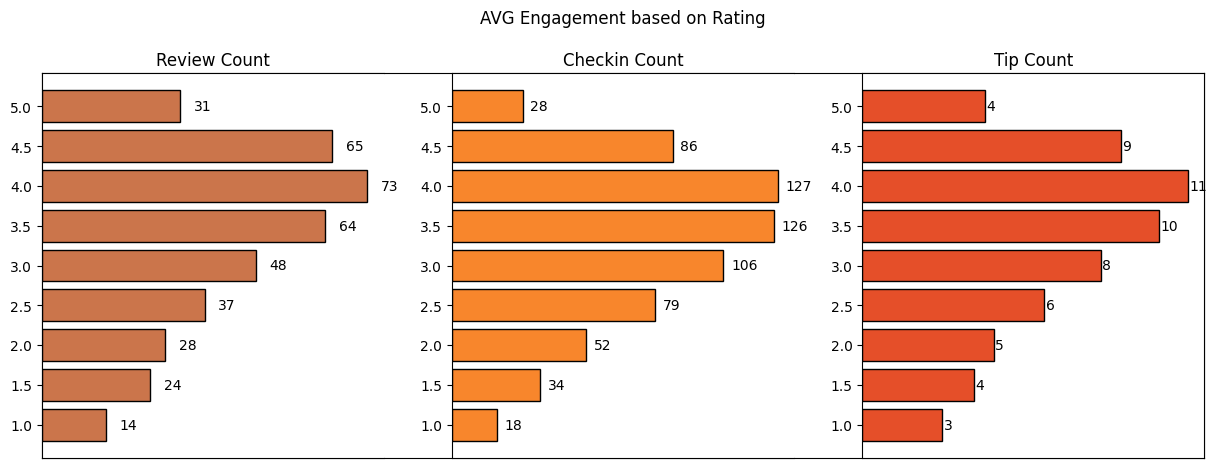

In [ ]:
plt.figure(figsize=(15,5))
plt.title('AVG Engagement based on Rating\n\n')
plt.yticks([])
plt.xticks([])
plt.subplot(1,3,1)
plt.title('Review Count')
plt.barh(review_count_df['rating'].astype('str'), review_count_df['avg_review_count'], edgecolor = 'k', color = '#CB754B')
plt.gca().spines['right'].set_visible(False)
for i, value in enumerate(review_count_df['avg_review_count']):
    plt.text(value+3, i, str(round(value)), color='black', va='center')

plt.xticks([])
plt.subplot(1,3,2)
plt.title('Checkin Count')
plt.barh(review_count_df['rating'].astype('str'), review_count_df['avg_checkin_count'], edgecolor = 'k', color = '#F8862C')
plt.gca().spines['right'].set_visible(False)
for i, value in enumerate(review_count_df['avg_checkin_count']):
    plt.text(value+3, i, str(round(value)), color='black', va='center')

plt.xticks([])
plt.subplot(1,3,3)
plt.title('Tip Count')
plt.barh(review_count_df['rating'].astype('str'), review_count_df['avg_tip_count'], edgecolor = 'k', color='#E54F29')
for i, value in enumerate(review_count_df['avg_tip_count']):
    plt.text(value+0.05, i, str(round(value)), color='black', va='center')
plt.xticks([])
plt.show()

In [ ]:
# Is there a corerelation between the number of reviews, tips, and check-ins for a business
pd.read_sql_query(f"""SELECT
    b.business_id,
    SUM(b.review_count) AS review_count,
    AVG(b.stars) AS avg_rating,
    SUM(LENGTH(cc.date) - LENGTH(REPLACE(cc.date, ',', '')) + 1) AS checkin_count,
    SUM(tip.tip_count) AS tip_count
FROM
    business b
LEFT JOIN
    checkin cc ON b.business_id = cc.business_id
LEFT JOIN
    (SELECT business_id, COUNT(business_id) AS tip_count FROM tip GROUP BY business_id) AS tip
    ON b.business_id = tip.business_id
WHERE b.business_id IN {tuple(business_id['business_id'])}
GROUP BY
    b.business_id
""", conn).dropna()

,business_id,review_count,avg_rating,checkin_count,tip_count
0,---kPU91CF4Lq2-WlRu9Lw,24,4.5,11.0,4.0
1,--0iUa4sNDFiZFrAdIWhZQ,14,3.0,10.0,6.0
2,--epgcb7xHGuJ-4PUeSLAw,34,3.0,118.0,6.0
4,--lqIzK-ZVTtgwiQM63XgQ,15,2.0,21.0,2.0
5,-09Oc2D14vRnmirPh0vlXw,135,3.0,500.0,25.0
...,...,...,...,...,...
31530,zzIF9qp2UoHN48EeZH_IDg,19,3.0,6.0,5.0
31532,zzbZtgPYZS8sTIWQH6DwEw,86,3.0,292.0,17.0
31533,zziDpuuJw-Km1J4BaGpBKA,6,3.5,20.0,2.0
31534,zzjFdJwXuxBOGe9JeY_EMw,47,4.0,27.0,2.0


In [ ]:
# Is there a correlation between the number of reviews, tips, and check-ins for a business?
engagement_df = pd.read_sql_query(f"""SELECT
    b.business_id,
    SUM(b.review_count) AS review_count,
    AVG(b.stars) AS avg_rating,
    SUM(LENGTH(cc.date) - LENGTH(REPLACE(cc.date, ',', '')) + 1) AS checkin_count,
    SUM(tip.tip_count) as tip_count,
    (CASE WHEN b.stars >= 3.5 Then 'High-Rated' Else 'Low-Rated' END) as category
FROM
    business b
LEFT JOIN
    checkin cc ON b.business_id = cc.business_id
LEFT JOIN
    (select business_id, count(business_id) as tip_count from tip GROUP BY business_id ORDER BY tip_count) as tip ON b.business_id = tip.business_id
WHERE b.business_id IN {tuple(business_id['business_id'])}
GROUP BY
    b.business_id
""", conn).dropna()

engagement_df[['review_count', 'checkin_count', 'tip_count']].corr()

,review_count,checkin_count,tip_count
review_count,1.000000,0.626884,0.766321
checkin_count,0.626884,1.000000,0.772088
tip_count,0.766321,0.772088,1.000000


In [ ]:
engagement_df[['review_count', 'checkin_count', 'tip_count']].corr()

,review_count,checkin_count,tip_count
review_count,1.000000,0.644334,0.767185
checkin_count,0.644334,1.000000,0.772088
tip_count,0.767185,0.772088,1.000000


<Axes: >

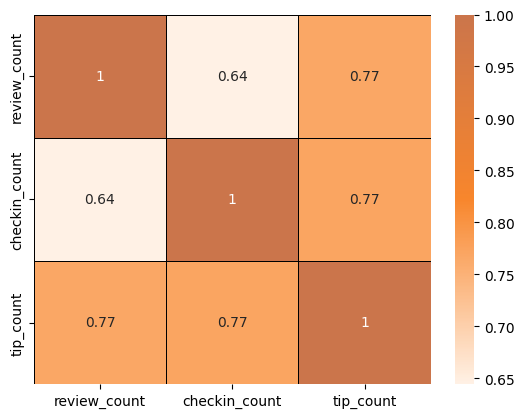

In [ ]:
colors = ['#FFF1E5', '#F8862C', '#CB754B']
custom_cmap = LinearSegmentedColormap.from_list('mycmap', colors)
sns.heatmap(engagement_df[['review_count', 'checkin_count', 'tip_count']].corr(), cmap = custom_cmap, annot = True, linewidths = 0.5, linecolor = 'black')

In [ ]:
#

,business_id,review_count,avg_rating,checkin_count,tip_count,category
0,---kPU91CF4Lq2-WlRu9Lw,24,4.5,11.0,4.0,High-Rated
1,--0iUa4sNDFiZFrAdIWhZQ,14,3.0,10.0,6.0,Low-Rated
2,--epgcb7xHGuJ-4PUeSLAw,34,3.0,118.0,6.0,Low-Rated
4,--lqIzK-ZVTtgwiQM63XgQ,15,2.0,21.0,2.0,Low-Rated
5,-09Oc2D14vRnmirPh0vlXw,135,3.0,500.0,25.0,Low-Rated
...,...,...,...,...,...,...
31530,zzIF9qp2UoHN48EeZH_IDg,19,3.0,6.0,5.0,Low-Rated
31532,zzbZtgPYZS8sTIWQH6DwEw,86,3.0,292.0,17.0,Low-Rated
31533,zziDpuuJw-Km1J4BaGpBKA,6,3.5,20.0,2.0,High-Rated
31534,zzjFdJwXuxBOGe9JeY_EMw,47,4.0,27.0,2.0,High-Rated


In [ ]:
engagement_df.groupby("category")[['review_count', 'tip_count', 'checkin_count']].mean()

,review_count,tip_count,checkin_count
category,,,
High-Rated,72.291062,10.162766,122.066641
Low-Rated,42.123420,6.541689,88.880828


In [ ]:
# Function to calculate the sucess score based on the avg rating  and total review count
def calculate_sucess_matric(df):
  success_score = []
  for index, row in df.iterrows():
    score = row['avg_rating'] * np.log(row['review_count'] + 1)
    success_score.append(score)
  return success_score


In [ ]:
# how do the sucess matrics (review_count or avg_rating) of restrurants very across different states or cities
city_df = pd.read_sql_query(f"""select city, state, latitude, longitude, AVG(stars) as avg_rating, SUM(review_count) as review_count,
count(*) as restaurant_count
from business
WHERE business_id IN {tuple(business_id['business_id'])}
group by state, city
order by review_count desc
limit 10""", conn)

city_df['succcess_score'] = calculate_sucess_matric(city_df)


In [ ]:
city_df

,city,state,latitude,longitude,avg_rating,review_count,restaurant_count,succcess_score
0,Philadelphia,PA,39.955505,-75.155564,3.532156,175487,3001,42.651934
1,Tampa,FL,27.890814,-82.502346,3.571429,104376,1715,41.270588
2,Indianapolis,IN,39.637133,-86.127217,3.412111,92639,1701,39.022521
3,Tucson,AZ,32.338572,-111.010760,3.386187,91613,1419,38.688341
4,Nashville,TN,36.208102,-86.768170,3.493590,87070,1404,39.737764
5,New Orleans,LA,29.963974,-90.042604,3.693676,69239,1012,41.167252
6,Saint Louis,MO,38.583223,-90.407187,3.414303,51490,811,37.042331
7,Reno,NV,39.476518,-119.784037,3.479626,48393,589,37.535187
8,Edmonton,AB,53.436403,-113.604288,3.509379,45916,1546,37.671748
9,Boise,ID,43.611192,-116.206275,3.558824,36104,561,37.346958


In [ ]:
import folium
import branca.colormap as cm

# 1. Create the missing 'success_score' column first (replace formula with your exact calculation if different)
city_df['success_score'] = city_df['review_count'] * city_df['avg_rating']

# 2. Create base map
m = folium.Map(location=[city_df['latitude'].mean(), city_df['longitude'].mean()], zoom_start=4)

# 3. Define color scale (using branca module to avoid class path errors)
color_scale = cm.LinearColormap(colors=['green', 'yellow', '#E54F29'],
                                vmin=city_df['success_score'].min(),
                                vmax=city_df['success_score'].max())

# 4. Add markers
for index, row in city_df.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=5,
        color=color_scale(row['success_score']),
        fill=True,
        fill_color=color_scale(row['success_score']),
        fill_opacity=0.7,
        popup=f"Success Score: {row['success_score']}"
    ).add_to(m)

# 5. Display color scale
m.add_child(color_scale)

In [ ]:
# Are there any patterns in user engagement over time for successful businesses compared to less successful ones?
# Are there any seasonal trends in the user engagement for restaurants?

high_rated_engagement = pd.read_sql_query(f"""
SELECT review.month_year, review.review_count, tip.tip_count FROM
(SELECT strftime('%m-%Y', date) AS month_year, COUNT(*) AS review_count
FROM review
WHERE business_id IN {tuple(business_id['business_id'])} and stars >= 3.5
GROUP BY month_year
ORDER BY month_year) as review
JOIN
(SELECT AVG(b.stars), strftime('%m-%Y', tip.date) AS month_year, COUNT(*) AS tip_count
FROM tip
JOIN business as b
on tip.business_id = b.business_id
WHERE tip.business_id IN {tuple(business_id['business_id'])} and b.stars >= 3.5
GROUP BY month_year
ORDER BY month_year) as tip

on review.month_year = tip.month_year
;""", conn)

low_rated_engagement = pd.read_sql_query(f"""
SELECT review.month_year, review.review_count, tip.tip_count FROM
(SELECT strftime('%m-%Y', date) AS month_year, COUNT(*) AS review_count
FROM review
WHERE business_id IN {tuple(business_id['business_id'])} and stars < 3.5
GROUP BY month_year
ORDER BY month_year) as review
JOIN
(SELECT AVG(b.stars), strftime('%m-%Y', tip.date) AS month_year, COUNT(*) AS tip_count
FROM tip
JOIN business as b
on tip.business_id = b.business_id
WHERE tip.business_id IN {tuple(business_id['business_id'])} and b.stars < 3.5
GROUP BY month_year
ORDER BY month_year) as tip

on review.month_year = tip.month_year
;""", conn)

In [ ]:
high_rated_engagement

,month_year,review_count,tip_count
0,01-2010,43,79
1,01-2011,45,621
2,01-2012,57,1321
3,01-2013,93,1230
4,01-2014,93,1357
...,...,...,...
107,12-2013,91,1278
108,12-2014,121,1065
109,12-2015,187,1457
110,12-2016,160,1540


In [ ]:
low_rated_engagement

,month_year,review_count,tip_count
0,01-2010,18,25
1,01-2011,27,297
2,01-2012,27,538
3,01-2013,44,548
4,01-2014,78,607
...,...,...,...
105,12-2013,70,552
106,12-2014,87,446
107,12-2015,87,496
108,12-2016,89,478


In [ ]:
time_rating = pd.read_sql_query(f"""SELECT strftime('%m-%Y',date) AS month_year, AVG(stars) as avg_rating
FROM review
WHERE business_id IN {tuple(business_id['business_id'])}
GROUP BY month_year
ORDER BY month_year
;""", conn)

In [ ]:
time_rating['month_year'] = pd.to_datetime(time_rating['month_year'])
time_rating.sort_values('month_year', inplace = True)
time_rating = time_rating[time_rating['month_year'] > '2017']

high_rated_engagement['month_year'] = pd.to_datetime(high_rated_engagement['month_year'])
high_rated_engagement.sort_values('month_year', inplace = True)
high_rated_engagement = high_rated_engagement[high_rated_engagement['month_year'] > '2017']

low_rated_engagement['month_year'] = pd.to_datetime(low_rated_engagement['month_year'])
low_rated_engagement.sort_values('month_year', inplace = True)
low_rated_engagement = low_rated_engagement[low_rated_engagement['month_year'] > '2017']

In [ ]:
high_rated_engagement['avg_rating'] = time_rating['avg_rating'].values


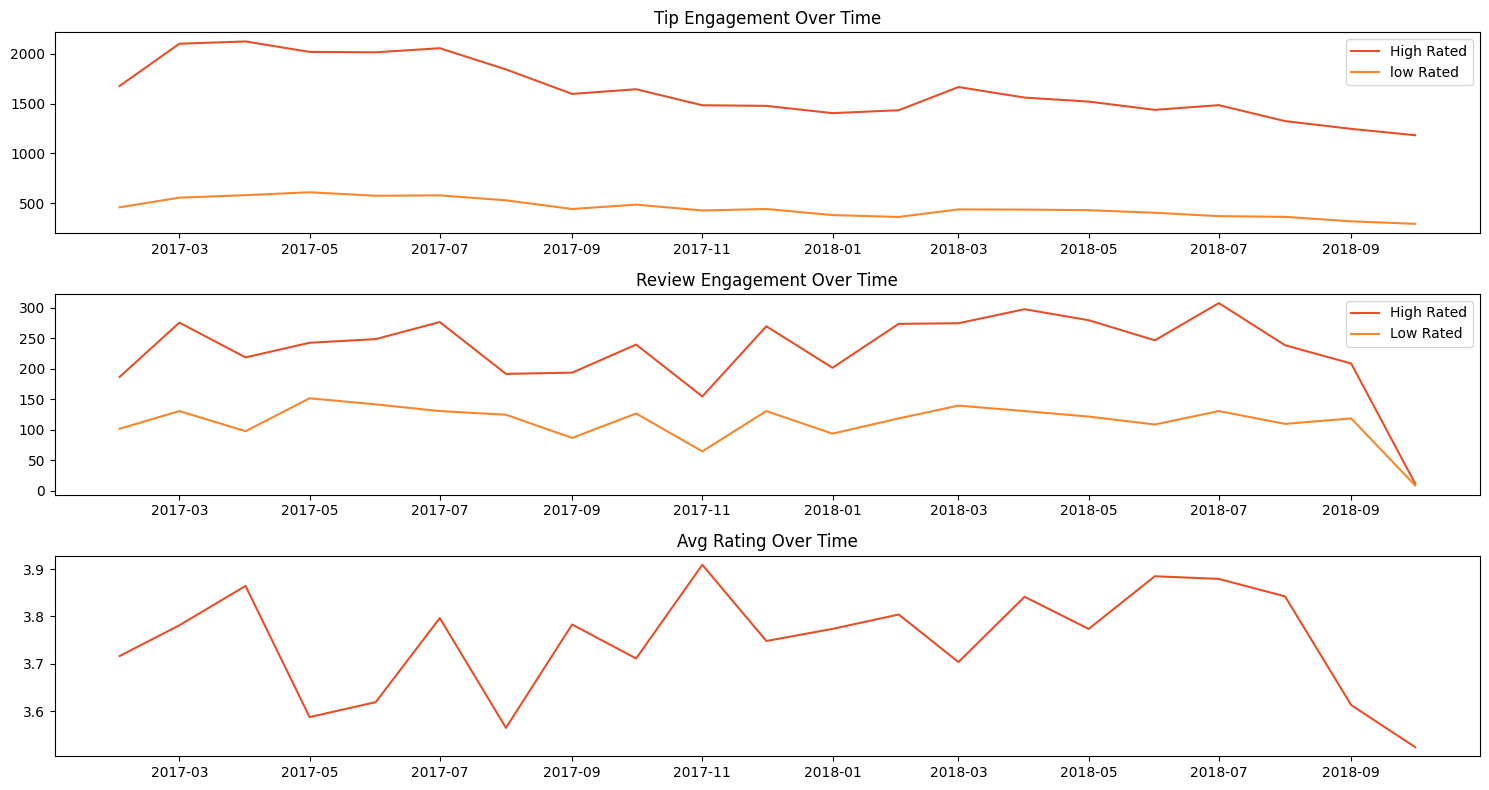

In [ ]:
plt.figure(figsize = (15,8))
plt.subplot(3,1,1)
plt.title('Tip Engagement Over Time')
plt.plot(high_rated_engagement['month_year'],high_rated_engagement['tip_count'], label = 'High Rated', color = '#E54F29')
plt.plot(low_rated_engagement['month_year'],low_rated_engagement['tip_count'], label = 'low Rated',color = '#F8862C')
plt.legend()
plt.subplot(3,1,2)
plt.title('Review Engagement Over Time')
plt.plot(high_rated_engagement['month_year'],high_rated_engagement['review_count'], label = 'High Rated', color = '#E54F29')
plt.plot(low_rated_engagement['month_year'],low_rated_engagement['review_count'], label = 'Low Rated', color = '#F8862C')
plt.legend()
plt.subplot(3,1,3)
plt.title('Avg Rating Over Time')
plt.plot(time_rating['month_year'],time_rating['avg_rating'], color = '#E54F29')
plt.tight_layout()
plt.show()

In [ ]:
tip_high_rated = high_rated_engagement[['month_year', 'tip_count']].set_index('month_year')
review_high_rated = high_rated_engagement[['month_year', 'review_count']].set_index('month_year')
rating_df = time_rating[['month_year', 'avg_rating']].set_index('month_year')

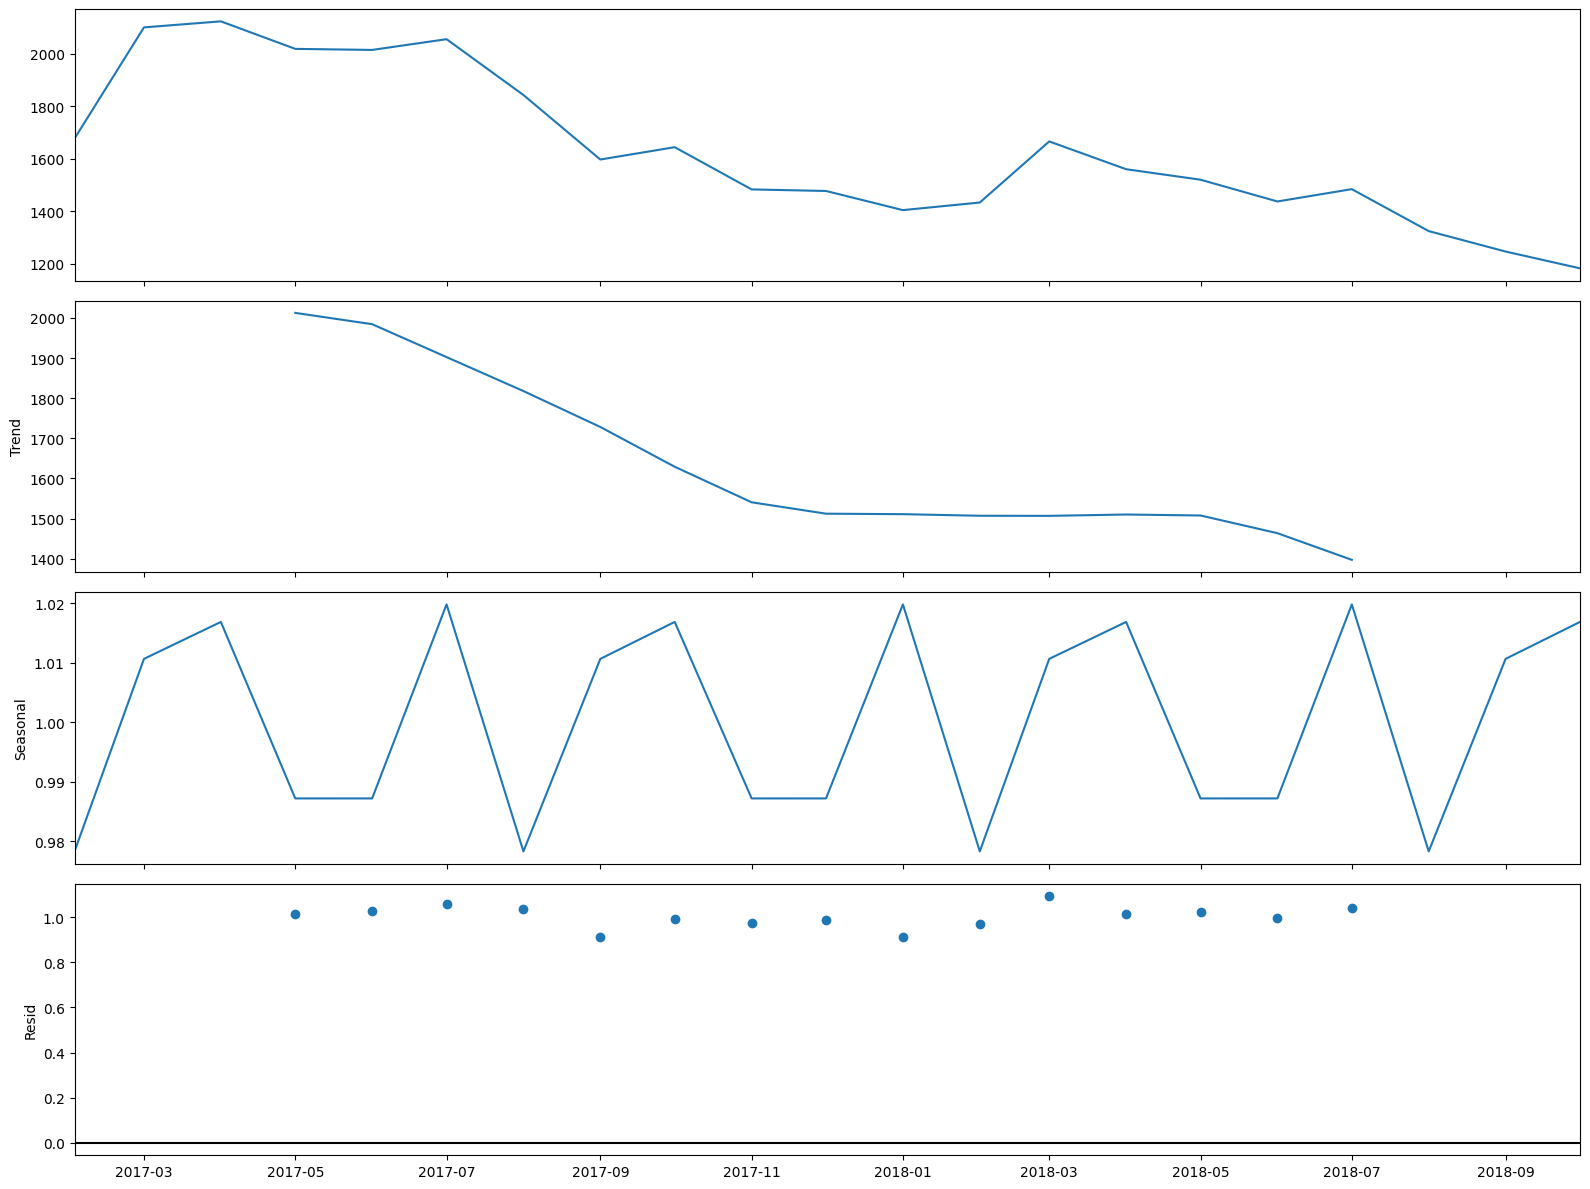

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
multiplicative_decomposition = seasonal_decompose(tip_high_rated, model='multiplicative', period = 6)
plt.rcParams.update({'figure.figsize': (16, 12)})
multiplicative_decomposition.plot()
plt.show()

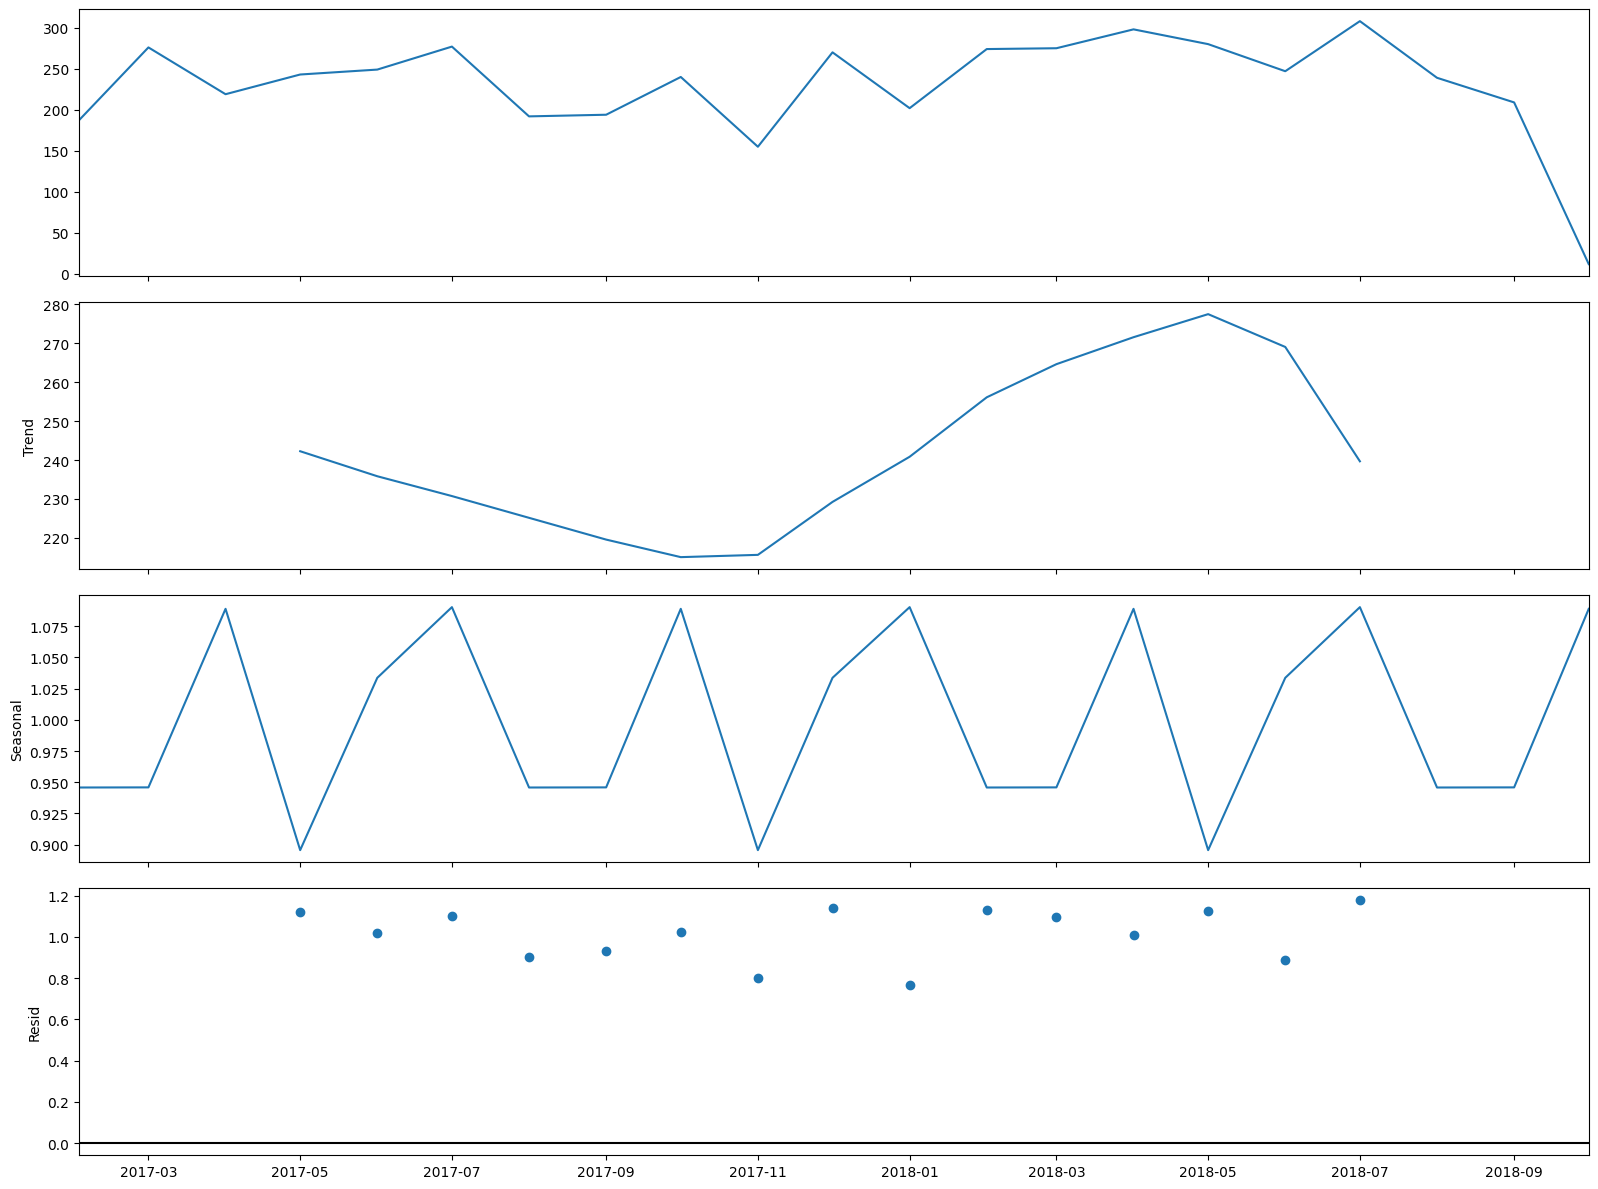

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
multiplicative_decomposition = seasonal_decompose(review_high_rated, model='multiplicative', period = 6)
plt.rcParams.update({'figure.figsize': (16, 12)})
multiplicative_decomposition.plot()
plt.show()

In [ ]:
# How does the sentiment of reviews and tips (useful, funny, cool) correlate with the success metrics of restaurants?

sentiment_df = pd.read_sql_query(f"""SELECT b.business_id, AVG(b.stars) as avg_rating, SUM(b.review_count) as review_count,
SUM(s.useful_count) as useful_count,
SUM(s.funny_count) as funny_count,
SUM(s.cool_count) as cool_count
FROM
(SELECT business_id,
    SUM(useful) as useful_count,
    SUM(funny) as funny_count,
    SUM(cool) as cool_count
FROM
    review
GROUP BY business_id) as s
JOIN business as b on b.business_id = s.business_id

WHERE b.business_id IN {tuple(business_id['business_id'])}
GROUP BY b.business_id
ORDER BY review_count""", conn)
sentiment_df = remove_outliers(sentiment_df, 'review_count')
sentiment_df = remove_outliers(sentiment_df, 'useful_count')
sentiment_df = remove_outliers(sentiment_df, 'funny_count')
sentiment_df = remove_outliers(sentiment_df, 'cool_count')

In [ ]:
sentiment_df['success_score'] = calculate_sucess_matric(sentiment_df)

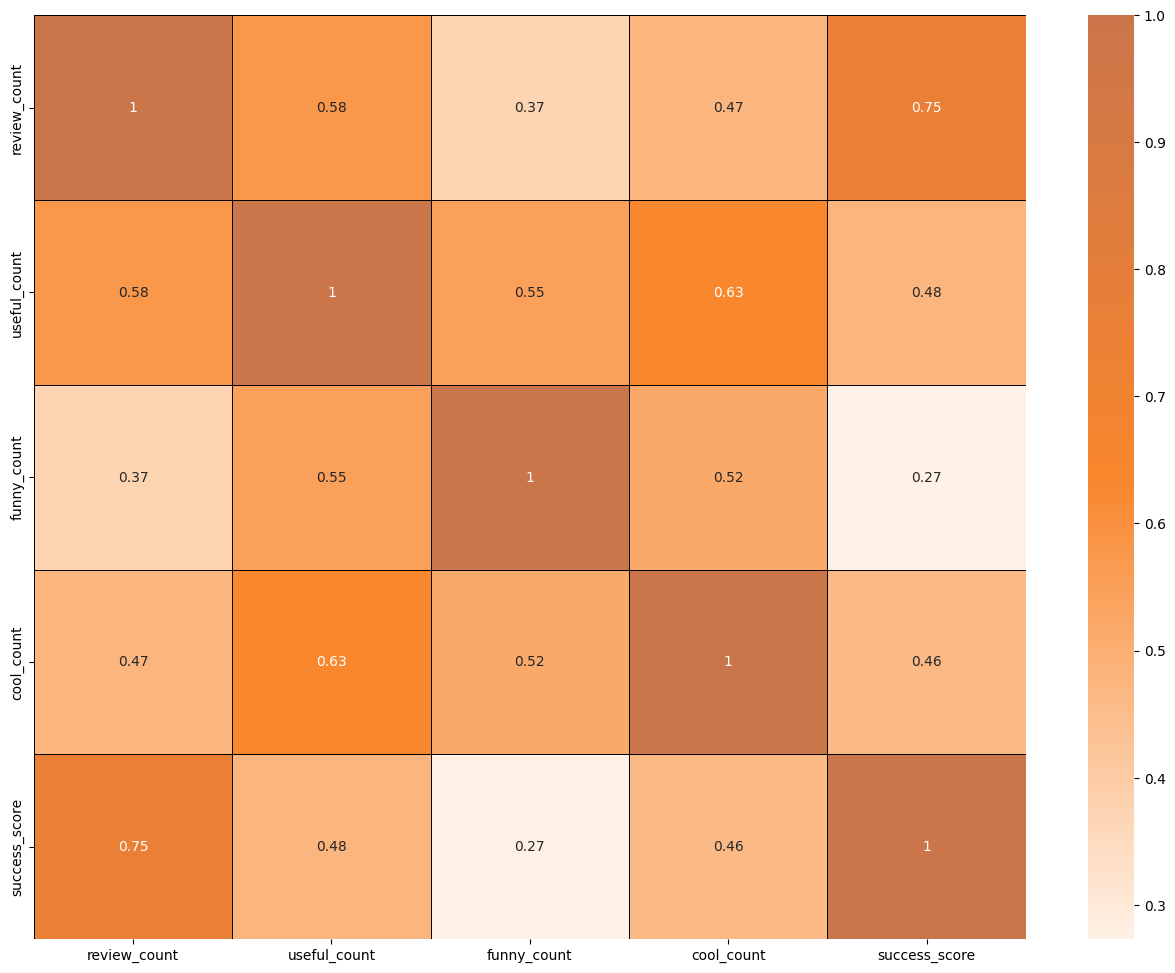

In [ ]:
sns.heatmap(sentiment_df.iloc[:,2:].corr(), cmap = custom_cmap, annot = True, linewidths = 0.5, linecolor = 'black')
plt.show()

In [ ]:
# Is there any difference in engagement of elite users and non elite users?
elite_df = pd.read_sql_query("""SELECT
    elite,
    COUNT(*) as num_users,
    SUM(review_count) AS total_review_count
FROM
    (SELECT
        CASE
            WHEN elite = '' THEN 'Not Elite'
            ELSE 'Elite'
        END AS elite,
        u.review_count
    FROM
        user u) AS user_elite
GROUP BY
    elite;
""", conn)

In [ ]:
elite_df

,elite,num_users,total_review_count
0,Elite,19862,6231756
1,Not Elite,80138,3031594


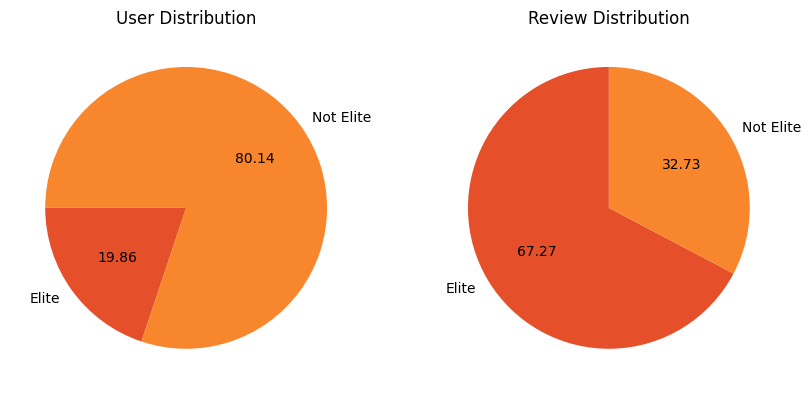

In [ ]:
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.title('User Distribution')
plt.pie(elite_df['num_users'], labels = elite_df['elite'], autopct='%.2f', startangle = 180, colors = ['#E54F29','#F8862C'])

plt.subplot(1,2,2)
plt.title('Review Distribution')
plt.pie(elite_df['total_review_count'], labels = elite_df['elite'], autopct='%.2f', startangle = 90, colors = ['#E54F29','#F8862C'])
plt.show()

In [ ]:
# What are the busiest hours for restaurants?

review_engagement = pd.read_sql_query("""SELECT
    cast (strftime('%H',date) as integer)
    as hour,
    COUNT(*) AS review_count
FROM
    review
GROUP BY
    hour;
""",conn)

tip_engagement = pd.read_sql_query("""SELECT
    cast (strftime('%H',date) as integer)
    as hour,
    COUNT(*) AS tip_count
FROM
    tip
GROUP BY
    hour;
""",conn)

checkin = pd.read_sql_query("""SELECT date FROM checkin""",conn)
checkin_engagement = []
for i in checkin['date']:
    checkin_engagement.extend([datetime.strptime(j.strip(),"%Y-%m-%d %H:%M:%S").strftime("%H") for j in i.split(',')])

checkin_engagement = pd.DataFrame(checkin_engagement).astype('int').groupby(0)[0].count()

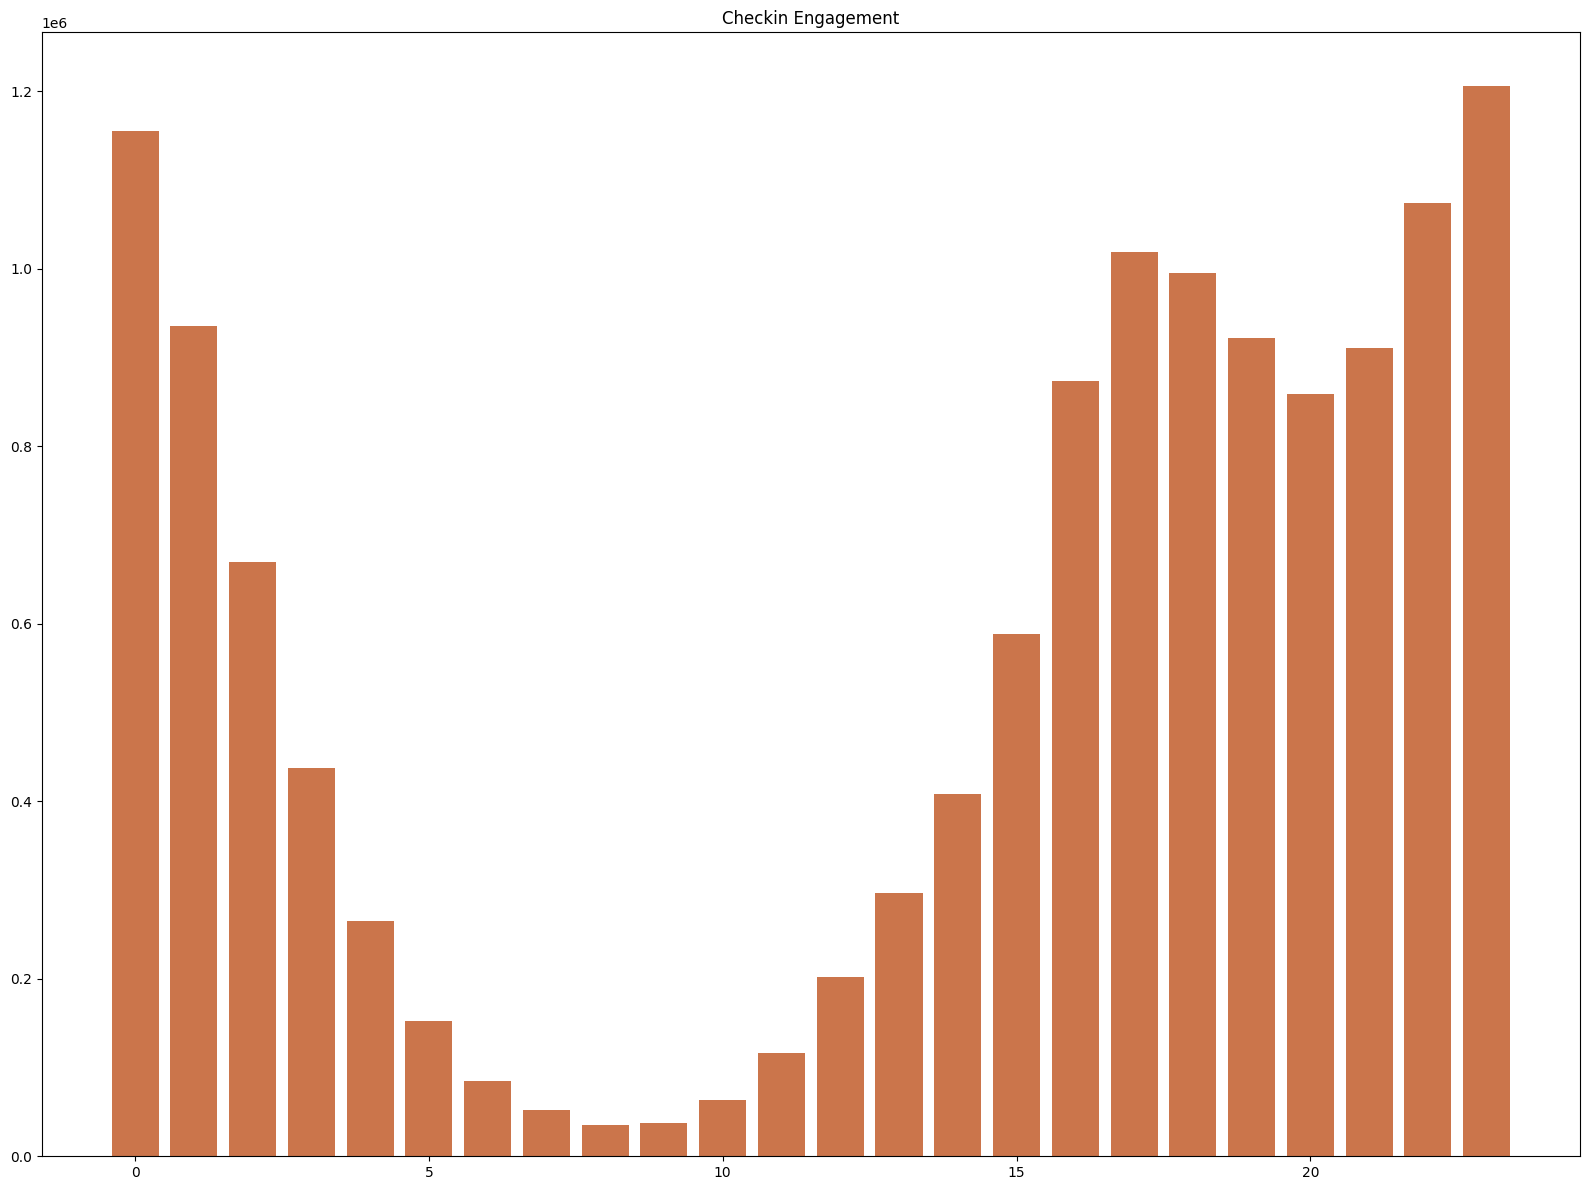

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Fast Vectorized Processing (Runs in seconds)
# Explode the dates if they are comma-separated strings/lists, then parse hour/month
dates_series = checkin['date'].dropna()

# If dates are comma-separated strings, split them into separate rows
if isinstance(dates_series.iloc[0], str):
    dates_series = dates_series.str.split(',')

# Flatten lists and convert directly using pandas vectorized datetime engine
expanded_dates = dates_series.explode().str.strip()
dt_series = pd.to_datetime(expanded_dates)

# Extract component (e.g., .dt.hour, .dt.month, or .dt.dayofweek depending on your graph)
checkin_counts = dt_series.dt.hour.value_counts().sort_index()

# 2. Plotting
plt.title('Checkin Engagement')
plt.bar(checkin_counts.index, checkin_counts.values, color='#CB754B')
plt.tight_layout()
plt.show()